# Wafer Guard: leakage-safe wafer defect detector

This notebook audits and repairs the supplied supervised autoencoder. The evaluation follows timestamp order, keeps the natural class distribution, and fits learned preprocessing only on the training period.

**Important:** this dataset is small and time-dependent. Results are a research audit, not evidence that a production release is safe.

## 1. Audit findings

1. **Data leakage:** the original notebook fits the imputer and scaler on all rows and applies SMOTE before the train/test split. This lets evaluation-population statistics and synthetic neighbours cross the split. It also randomly shuffles time-ordered lots. The repair splits chronologically first, fits preprocessing only on the training period, and does not use SMOTE.
2. **Corrupted reconstruction gradients:** the original loader creates inputs with shape `[B, 1, F]`, while the decoder returns `[B, F]`. Subtraction broadcasts to `[B, B, F]`, coupling different wafers in the loss. The repair uses `[B, F]` throughout and asserts exact shape equality before MSE.
3. **Invariant blindness:** a production monitor must not permanently discard a channel merely because it is constant during the historical training window: a later departure from that baseline can itself be an excursion. The repair retains channels, records training-period invariant baselines, and adds a transparent rule-based alarm when a previously invariant sensor changes. This is a forward-monitoring guardrail, not a claim that the current dataset's labels prove these deviations are defects.

The notebook also handles the PS-L legacy sentinel explicitly: `sensor_0 == 0.0` marks legacy rows; `sensor_1` values on those rows are categorical codes, not continuous measurements.

## 2. Imports and reproducibility

In [1]:
import os, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)

SEED = 1337
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch:', torch.__version__, '| device:', DEVICE)

torch: 2.10.0+cpu | device: cpu


## 3. Load and inspect data

The supplied CSV is expected in the same directory as this notebook. Rows are sorted by timestamp before any split.

In [2]:
DATA_PATH = 'secom_telemetry_modified.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f'{DATA_PATH} must be placed beside this notebook.')
df = pd.read_csv(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')
SENSOR_COLS = [c for c in df.columns if c.startswith('sensor_')]
assert len(SENSOR_COLS) == 590
assert set(df['label'].unique()).issubset({-1, 1})
df = df.sort_values('timestamp', kind='stable').reset_index(drop=True)
y = (df['label'].to_numpy() == 1).astype(np.int64)
print('rows:', len(df), '| sensors:', len(SENSOR_COLS), '| missing sensor cells:', int(df[SENSOR_COLS].isna().sum().sum()))
print('defects:', int(y.sum()), '| natural prevalence:', f'{y.mean():.2%}')
print('timestamps monotonic:', df['timestamp'].is_monotonic_increasing)
df[['timestamp', 'label']].head()

rows: 1567 | sensors: 590 | missing sensor cells: 41948
defects: 104 | natural prevalence: 6.64%
timestamps monotonic: True


,timestamp,label
0,2008-07-19 11:55:00,-1
1,2008-07-19 12:32:00,-1
2,2008-07-19 13:17:00,1
3,2008-07-19 14:43:00,-1
4,2008-07-19 15:22:00,-1


## 4. Chronological split and PS-L business logic

The first 70% of lots are training data, the next 15% validation data, and the final 15% test data. No row is shuffled across time. `sensor_0 == 0.0` is used exactly as the specified PS-L sentinel. Only on those rows is `sensor_1` interpreted as a categorical code.

In [3]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
train_idx = np.arange(0, train_end)
val_idx = np.arange(train_end, val_end)
test_idx = np.arange(val_end, n)

y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print('split | n | defects | prevalence | start | end')
for name, idx, yy in [('train', train_idx, y_train), ('validation', val_idx, y_val), ('test', test_idx, y_test)]:
    print(f'{name:10s} | {len(idx):4d} | {int(yy.sum()):3d} | {yy.mean():.2%} | {df.timestamp.iloc[idx[0]]} | {df.timestamp.iloc[idx[-1]]}')

raw = df[SENSOR_COLS].astype(float).copy()
ps_l = raw['sensor_0'].eq(0.0).to_numpy()
code_values = [100.0, 200.0, 300.0]
legacy_codes = raw['sensor_1'].to_numpy()
unknown_legacy_codes = ps_l & ~np.isin(legacy_codes, code_values)
assert not unknown_legacy_codes.any(), 'Unexpected PS-L sensor_1 code found; inspect before modeling.'
print('PS-L sentinel rows:', int(ps_l.sum()))
print('PS-L code counts:', {int(c): int((ps_l & (legacy_codes == c)).sum()) for c in code_values})

# Remove sentinel values from continuous channels and represent the code categorically.
X_raw = raw.copy()
X_raw.loc[ps_l, 'sensor_0'] = np.nan
X_raw.loc[ps_l, 'sensor_1'] = np.nan
code_features = pd.DataFrame({f'ps_l_code_{int(c)}': (ps_l & (legacy_codes == c)).astype(float) for c in code_values}, index=df.index)
code_features['is_ps_l_legacy'] = ps_l.astype(float)
# Fit invariant baselines from training period only. Keep these channels in the model input.
train_raw = X_raw.iloc[train_idx]
invariant_baseline = {}
for col in SENSOR_COLS:
    observed = train_raw[col].dropna()
    if len(observed) and observed.nunique() == 1:
        invariant_baseline[col] = float(observed.iloc[0])
print('training-period invariant channels:', len(invariant_baseline))

split | n | defects | prevalence | start | end
train      | 1096 |  78 | 7.12% | 2008-07-19 11:55:00 | 2008-09-26 02:26:00
validation |  235 |  17 | 7.23% | 2008-09-26 03:12:00 | 2008-10-05 18:59:00
test       |  236 |   9 | 3.81% | 2008-10-05 19:45:00 | 2008-10-17 06:07:00
PS-L sentinel rows: 146
PS-L code counts: {100: 61, 200: 35, 300: 50}
training-period invariant channels: 122


## 5. Train-only preprocessing and invariant monitoring

Imputation and scaling are fitted on the training period only. Channels that are constant in the training period are retained in the continuous matrix: with a training-fitted `StandardScaler`, a later departure from that baseline maps away from zero. Because the model has never seen a nonzero training example for those channels, we **do not pretend it has learned their failure behaviour**. Instead, a separate, transparent invariant-deviation rule monitors them. Its alerts are reported separately from classifier metrics.


In [4]:
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
scaler = StandardScaler()
X_train_raw = X_raw.iloc[train_idx]
X_val_raw = X_raw.iloc[val_idx]
X_test_raw = X_raw.iloc[test_idx]
X_train_imp = imputer.fit_transform(X_train_raw)
X_val_imp = imputer.transform(X_val_raw)
X_test_imp = imputer.transform(X_test_raw)
X_train_cont = scaler.fit_transform(X_train_imp)
X_val_cont = scaler.transform(X_val_imp)
X_test_cont = scaler.transform(X_test_imp)

# Flags are computed from raw values against baselines learned from training only.
# Missing values are not treated as numeric deviations; imputation handles them separately.
def invariant_flags(frame):
    flags = []
    for col, baseline in invariant_baseline.items():
        vals = frame[col].to_numpy(dtype=float)
        flags.append((np.isfinite(vals) & (np.abs(vals - baseline) > 1e-8)).astype(np.float32))
    if not flags:
        return np.zeros((len(frame), 0), dtype=np.float32)
    return np.column_stack(flags).astype(np.float32)

inv_train = invariant_flags(X_train_raw)
inv_val = invariant_flags(X_val_raw)
inv_test = invariant_flags(X_test_raw)
inv_count_train, inv_count_val, inv_count_test = inv_train.sum(axis=1), inv_val.sum(axis=1), inv_test.sum(axis=1)

# Model input contains scaled sensor values and explicit PS-L categorical indicators.
# Do NOT append invariant flags to the learned model: all such flags are zero in
# training by construction, so the classifier cannot learn their effect.
def assemble(X_cont, idx):
    return np.concatenate([X_cont.astype(np.float32), code_features.iloc[idx].to_numpy(dtype=np.float32)], axis=1).astype(np.float32)
X_train = assemble(X_train_cont, train_idx)
X_val = assemble(X_val_cont, val_idx)
X_test = assemble(X_test_cont, test_idx)
print('feature matrix:', X_train.shape, X_val.shape, X_test.shape)
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
print('invariant deviations | train:', int(inv_count_train.sum()), '| validation:', int(inv_count_val.sum()), '| test:', int(inv_count_test.sum()))


feature matrix: (1096, 594) (235, 594) (236, 594)
invariant deviations | train: 0 | validation: 0 | test: 6


## 6. Supervised autoencoder

Inputs are `[batch, features]`; decoder outputs must match that exact shape. The positive-class weight addresses imbalance without manufacturing synthetic test examples.

In [5]:
class WaferSAE(nn.Module):
    def __init__(self, d_in, hidden=192, latent=24):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d_in, hidden), nn.LayerNorm(hidden), nn.GELU(),
                                     nn.Dropout(0.10), nn.Linear(hidden, hidden // 2),
                                     nn.GELU(), nn.Linear(hidden // 2, latent))
        self.decoder = nn.Sequential(nn.Linear(latent, hidden // 2), nn.GELU(),
                                     nn.Linear(hidden // 2, hidden), nn.GELU(), nn.Linear(hidden, d_in))
        self.head = nn.Linear(latent, 1)
    def forward(self, x):
        assert x.ndim == 2, f'Expected [B,F], received {tuple(x.shape)}'
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        logits = self.head(z).squeeze(-1)
        assert reconstruction.shape == x.shape, f'{reconstruction.shape} != {x.shape}'
        assert logits.shape == x.shape[:1]
        return reconstruction, logits, z

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32)))
val_tensor = torch.from_numpy(X_val).to(DEVICE)
y_val_t = torch.from_numpy(y_val.astype(np.float32)).to(DEVICE)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
model = WaferSAE(X_train.shape[1]).to(DEVICE)
pos_weight = torch.tensor([(len(y_train) - y_train.sum()) / max(y_train.sum(), 1)], dtype=torch.float32, device=DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-4)
bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print('parameters:', sum(p.numel() for p in model.parameters()), '| pos_weight:', float(pos_weight.item()))

# Explicit one-batch gradient/shape smoke test before full training.
xb, yb = next(iter(train_loader)); xb, yb = xb.to(DEVICE), yb.to(DEVICE)
recon, logits, _ = model(xb)
assert recon.shape == xb.shape
smoke_loss = ((recon - xb) ** 2).mean() + bce(logits, yb)
optimizer.zero_grad(set_to_none=True); smoke_loss.backward()
assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
print('gradient smoke test passed; input/reconstruction shape:', tuple(xb.shape), tuple(recon.shape))

parameters: 271171 | pos_weight: 13.051281929016113
gradient smoke test passed; input/reconstruction shape: (64, 594) (64, 594)


## 7. Train with validation-based early stopping

Average precision is monitored on the naturally imbalanced validation period. The test period is not used for model selection or threshold selection.

epoch 01 | loss=2.0167 | val AP=0.0651 | best=0.0651


epoch 05 | loss=0.8439 | val AP=0.0728 | best=0.0728


epoch 10 | loss=0.6840 | val AP=0.0647 | best=0.0728


early stopping at epoch 13
best epoch: 5 | best validation AP: 0.0728


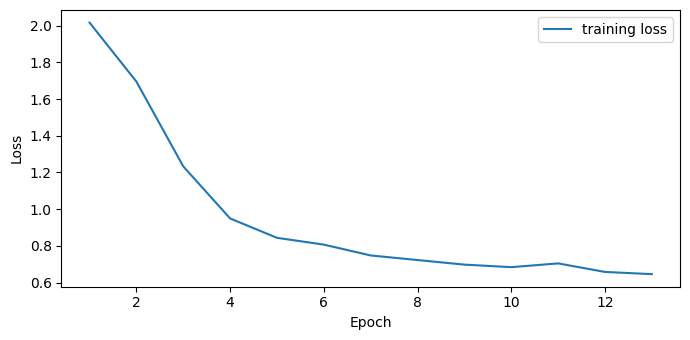

In [6]:
def evaluate_logits(model, X_np):
    model.eval()
    with torch.no_grad():
        _, logits, _ = model(torch.from_numpy(X_np).to(DEVICE))
        return torch.sigmoid(logits).cpu().numpy()

best_state = None
best_ap = -np.inf
best_epoch = 0
patience, stale, max_epochs = 8, 0, 50
history = []
for epoch in range(1, max_epochs + 1):
    model.train(); totals = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        recon, logits, _ = model(xb)
        assert recon.shape == xb.shape
        recon_loss = torch.mean((recon - xb) ** 2)
        clf_loss = bce(logits, yb)
        loss = recon_loss + clf_loss
        optimizer.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
        totals.append((loss.item(), recon_loss.item(), clf_loss.item()))
    val_prob = evaluate_logits(model, X_val)
    val_ap = average_precision_score(y_val, val_prob)
    history.append([epoch, *np.mean(totals, axis=0), val_ap])
    if val_ap > best_ap + 1e-5:
        best_ap, best_epoch, stale = val_ap, epoch, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        stale += 1
    if epoch == 1 or epoch % 5 == 0:
        print(f'epoch {epoch:02d} | loss={np.mean(totals,axis=0)[0]:.4f} | val AP={val_ap:.4f} | best={best_ap:.4f}')
    if stale >= patience:
        print('early stopping at epoch', epoch); break
model.load_state_dict(best_state)
print('best epoch:', best_epoch, '| best validation AP:', round(best_ap, 4))
history_df = pd.DataFrame(history, columns=['epoch','total_loss','reconstruction_loss','classification_loss','validation_ap'])
plt.figure(figsize=(7,3.5)); plt.plot(history_df.epoch, history_df.total_loss, label='training loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout(); plt.show()

## 8. Choose threshold on validation only

The classifier threshold is chosen to maximize validation F1 using classifier probabilities only. The invariant monitor is a separate operational alert and is not silently OR-ed into classifier predictions; this keeps the threshold objective and reported classifier metrics consistent. With few defects, the selected threshold is uncertain.


In [7]:
val_prob = evaluate_logits(model, X_val)
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
if len(thresholds):
    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best_i = int(np.argmax(f1_values))
    threshold = float(thresholds[best_i])
else:
    threshold = 0.5
val_pred = (val_prob >= threshold).astype(int)
print('validation-selected classifier threshold:', threshold)
print('validation prevalence:', f'{y_val.mean():.2%}', '| AP:', round(average_precision_score(y_val, val_prob), 4), '| ROC-AUC:', round(roc_auc_score(y_val, val_prob), 4))
print('classifier validation | precision:', round(precision_score(y_val, val_pred, zero_division=0), 4), '| recall:', round(recall_score(y_val, val_pred, zero_division=0), 4), '| F1:', round(f1_score(y_val, val_pred, zero_division=0), 4))
print('separate invariant monitor | validation rows flagged:', int((inv_count_val > 0).sum()), '| flagged defects:', int(((inv_count_val > 0) & (y_val == 1)).sum()))


validation-selected classifier threshold: 1.8332851823288365e-06
validation prevalence: 7.23% | AP: 0.0728 | ROC-AUC: 0.4682
classifier validation | precision: 0.0773 | recall: 1.0 | F1: 0.1435
separate invariant monitor | validation rows flagged: 0 | flagged defects: 0


## 9. Final test evaluation

The final chronological test period is evaluated once at its observed prevalence. Classifier metrics below use only the validation-selected classifier threshold. The invariant monitor is reported separately as a rule-based alert; it is not combined into the classifier confusion matrix. This avoids mixing a learned score with a deterministic rule while still making invariant departures visible.


In [8]:
test_prob = evaluate_logits(model, X_test)
test_pred = (test_prob >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0,1]).ravel()
metrics = {
    'samples': len(y_test),
    'defects': int(y_test.sum()),
    'prevalence': float(y_test.mean()),
    'dataset_prevalence': float(y.mean()),
    'threshold_from_validation': threshold,
    'classifier_precision': precision_score(y_test, test_pred, zero_division=0),
    'classifier_recall': recall_score(y_test, test_pred, zero_division=0),
    'classifier_f1': f1_score(y_test, test_pred, zero_division=0),
    'classifier_roc_auc': roc_auc_score(y_test, test_prob),
    'classifier_average_precision': average_precision_score(y_test, test_prob),
    'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    'invariant_monitor_flagged_rows': int((inv_count_test > 0).sum()),
    'invariant_monitor_flagged_defects': int(((inv_count_test > 0) & (y_test == 1)).sum()),
}
for k,v in metrics.items(): print(f'{k}: {v:.4f}' if isinstance(v, float) else f'{k}: {v}')
print('classifier confusion matrix [[TN, FP], [FN, TP]]:'); print(np.array([[tn,fp],[fn,tp]]))
print('baseline dataset defect prevalence:', f'{y.mean():.2%}')
print('Release recommendation: NO-GO for production without further validation and operational review.')


samples: 236
defects: 9
prevalence: 0.0381
dataset_prevalence: 0.0664
threshold_from_validation: 0.0000
classifier_precision: 0.0398
classifier_recall: 1.0000
classifier_f1: 0.0766
classifier_roc_auc: 0.6260
classifier_average_precision: 0.0779
tn: 10
fp: 217
fn: 0
tp: 9
invariant_monitor_flagged_rows: 1
invariant_monitor_flagged_defects: 0
classifier confusion matrix [[TN, FP], [FN, TP]]:
[[ 10 217]
 [  0   9]]
baseline dataset defect prevalence: 6.64%
Release recommendation: NO-GO for production without further validation and operational review.


## 10. Limitations and reproducibility

- The chronological test window has only a small number of defective lots, so F1 and recall are high-variance estimates.
- Defect prevalence can shift over time; the test prevalence should be reported rather than forced to match the overall 6.6% rate.
- The invariant alarm is a conservative monitoring guardrail. A deviation from a historical invariant is not proof of a defective wafer and requires domain review.
- No evaluator-only mask, hidden labels, or external target information is used.
- Save this notebook with the supplied CSV beside it and execute all cells from a clean kernel to reproduce results.